**Exploratory Data Analysis**

In [187]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Note**
The data is not saved within this repository. You will need to import it into this working directory. After that, run the cell below. 

In [188]:
df = pd.read_csv('ENB2012_data.csv')
df.head(4)

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2.0,0.0,0.0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3.0,0.0,0.0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4.0,0.0,0.0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5.0,0.0,0.0,15.55,21.33


**Note** The dataframe lacks the descirptive titles for each feature, so the below cell renames them, while also adding additional information. 

In [189]:
df.rename(columns={'X1':'Relative Compactness',
                    'X2':'Surface Area',
                    'X3':'Wall Area (m^2)',
                    'X4':'Roof Area (m^2)',
                    'X5':'Overall Height (m)',
                    'X6':'Orientation',
                    'X7':'Glazing Area',
                    'X8':'Glazing Area Distribution',
                    'Y1':'Heating Load',
                    'Y2':'Cooling Load'}, 
                    inplace=True)

In [190]:
df.head(4)

,Relative Compactness,Surface Area,Wall Area (m^2),Roof Area (m^2),Overall Height (m),Orientation,Glazing Area,Glazing Area Distribution,Heating Load,Cooling Load
0,0.98,514.5,294.0,110.25,7.0,2.0,0.0,0.0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3.0,0.0,0.0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4.0,0.0,0.0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5.0,0.0,0.0,15.55,21.33


In [191]:
#There are 528 rows of null data in the dataset. We will drop them since they are not many and we have enough data to work with.
df.isnull().sum()

Relative Compactness         528
Surface Area                 528
Wall Area (m^2)              528
Roof Area (m^2)              528
Overall Height (m)           528
Orientation                  528
Glazing Area                 528
Glazing Area Distribution    528
Heating Load                 528
Cooling Load                 528
dtype: int64

These 528 rows are rows of data tha follow the 768th row of actual data. These rows have nothing in them, and accoring to the introductory paper there are only 768 rows of data. This makes them safe to remove from our dataset.

In [192]:
#removed null values
df.dropna(inplace=True)
df.isnull().sum()

Relative Compactness         0
Surface Area                 0
Wall Area (m^2)              0
Roof Area (m^2)              0
Overall Height (m)           0
Orientation                  0
Glazing Area                 0
Glazing Area Distribution    0
Heating Load                 0
Cooling Load                 0
dtype: int64

In [193]:
#Check for duplicates
df.duplicated().sum()

0

In [194]:
df.nunique()

Relative Compactness          12
Surface Area                  12
Wall Area (m^2)                7
Roof Area (m^2)                4
Overall Height (m)             2
Orientation                    4
Glazing Area                   4
Glazing Area Distribution      6
Heating Load                 586
Cooling Load                 636
dtype: int64

In [195]:
df[['Orientation', 'Glazing Area Distribution']] = df[['Orientation', 'Glazing Area Distribution']].astype('category')

In [196]:
df.describe(include='number').style.format("{:.2f}")

,Relative Compactness,Surface Area,Wall Area (m^2),Roof Area (m^2),Overall Height (m),Glazing Area,Heating Load,Cooling Load
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,0.76,671.71,318.50,176.60,5.25,0.23,22.31,24.59
std,0.11,88.09,43.63,45.17,1.75,0.13,10.09,9.51
min,0.62,514.50,245.00,110.25,3.50,0.00,6.01,10.90
25%,0.68,606.38,294.00,140.88,3.50,0.10,12.99,15.62
50%,0.75,673.75,318.50,183.75,5.25,0.25,18.95,22.08
75%,0.83,741.12,343.00,220.50,7.00,0.40,31.67,33.13
max,0.98,808.50,416.50,220.50,7.00,0.40,43.10,48.03


In [197]:
df.to_csv('ENB2012_data_cleaned.csv', index=False)

In [198]:
df.describe(include='category').style.format("{:.2f}") #all Data are numeric and there are no missing values.

,Orientation,Glazing Area Distribution
count,768.00,768.00
unique,4.00,6.00
top,2.00,1.00
freq,192.00,144.00


Text(0, 0.5, 'Frequency')

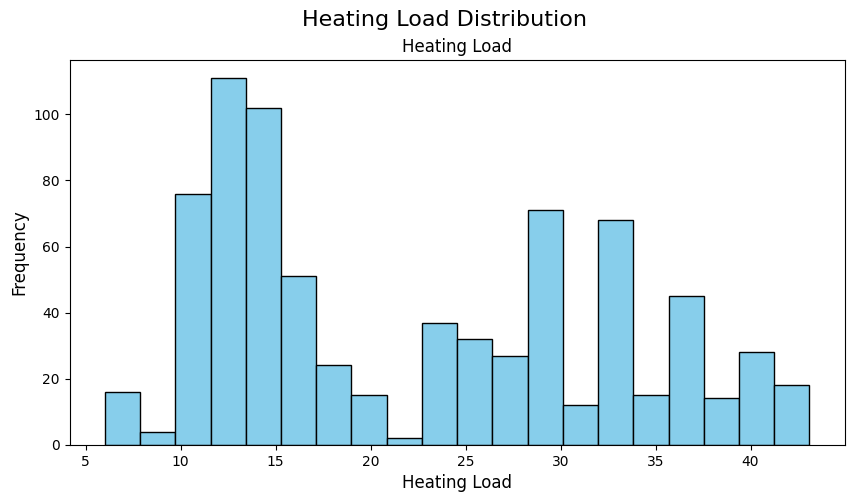

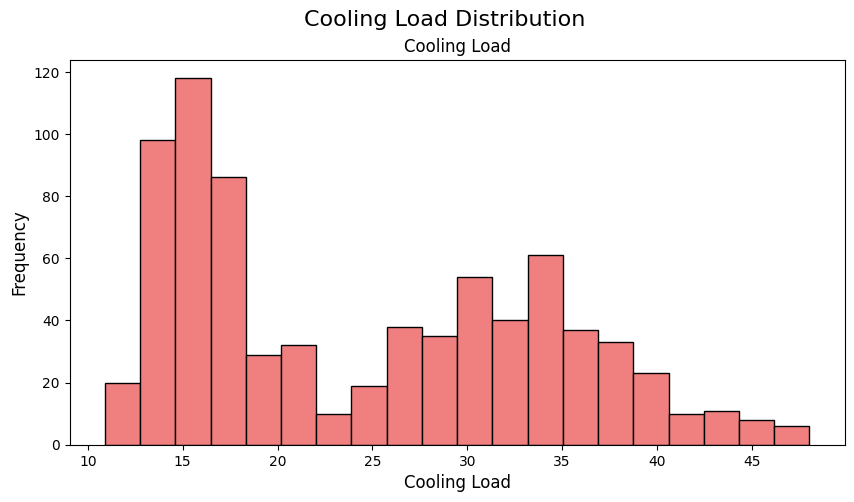

In [199]:
#Histograms for Heating Load and Cooling Load
ax = df[['Heating Load']].hist(bins=20, figsize=(10, 5), grid=False, color='skyblue', edgecolor='black')
plt.suptitle('Heating Load Distribution', fontsize=16)
plt.xlabel('Heating Load', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

ax = df[['Cooling Load']].hist(bins=20, figsize=(10, 5), grid=False, color='lightcoral', edgecolor='black')
plt.suptitle('Cooling Load Distribution', fontsize=16)
plt.xlabel('Cooling Load', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

Both targets have mild positive skewness, with means exceeding their medians. The histograms show multiple peaks or clusters.

In [200]:
loads = df[['Heating Load', 'Cooling Load']]

summary = loads.agg(['mean', 'median']).T
display(summary)

,mean,median
Heating Load,22.307201,18.95
Cooling Load,24.587760,22.08


,Heating Load,Cooling Load
Heating Load,1.000000,0.975862
Cooling Load,0.975862,1.000000


,Heating Load,Cooling Load
Heating Load,1.000000,0.972689
Cooling Load,0.972689,1.000000


Share of low-heating designs also low-cooling: 87.0%


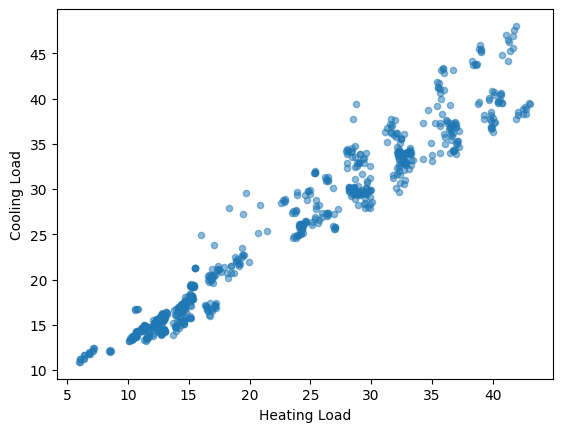

In [201]:
heating = "Heating Load"
cooling = "Cooling Load"

display(df[[heating, cooling]].corr(method="pearson"))
display(df[[heating, cooling]].corr(method="spearman"))

ax = df.plot.scatter(x=heating, y=cooling, alpha=0.5)

low_heating = df[heating] <= df[heating].quantile(0.25)
low_cooling = df[cooling] <= df[cooling].quantile(0.25)

print(
    "Share of low-heating designs also low-cooling:",
    f"{low_cooling[low_heating].mean():.1%}"
)

Heating and cooling loads are strongly positively associated (Pearson r = 0.976; Spearman ρ = 0.973). Among designs in the lowest heating-load quartile, 87.0% also fall in the lowest cooling-load quartile.

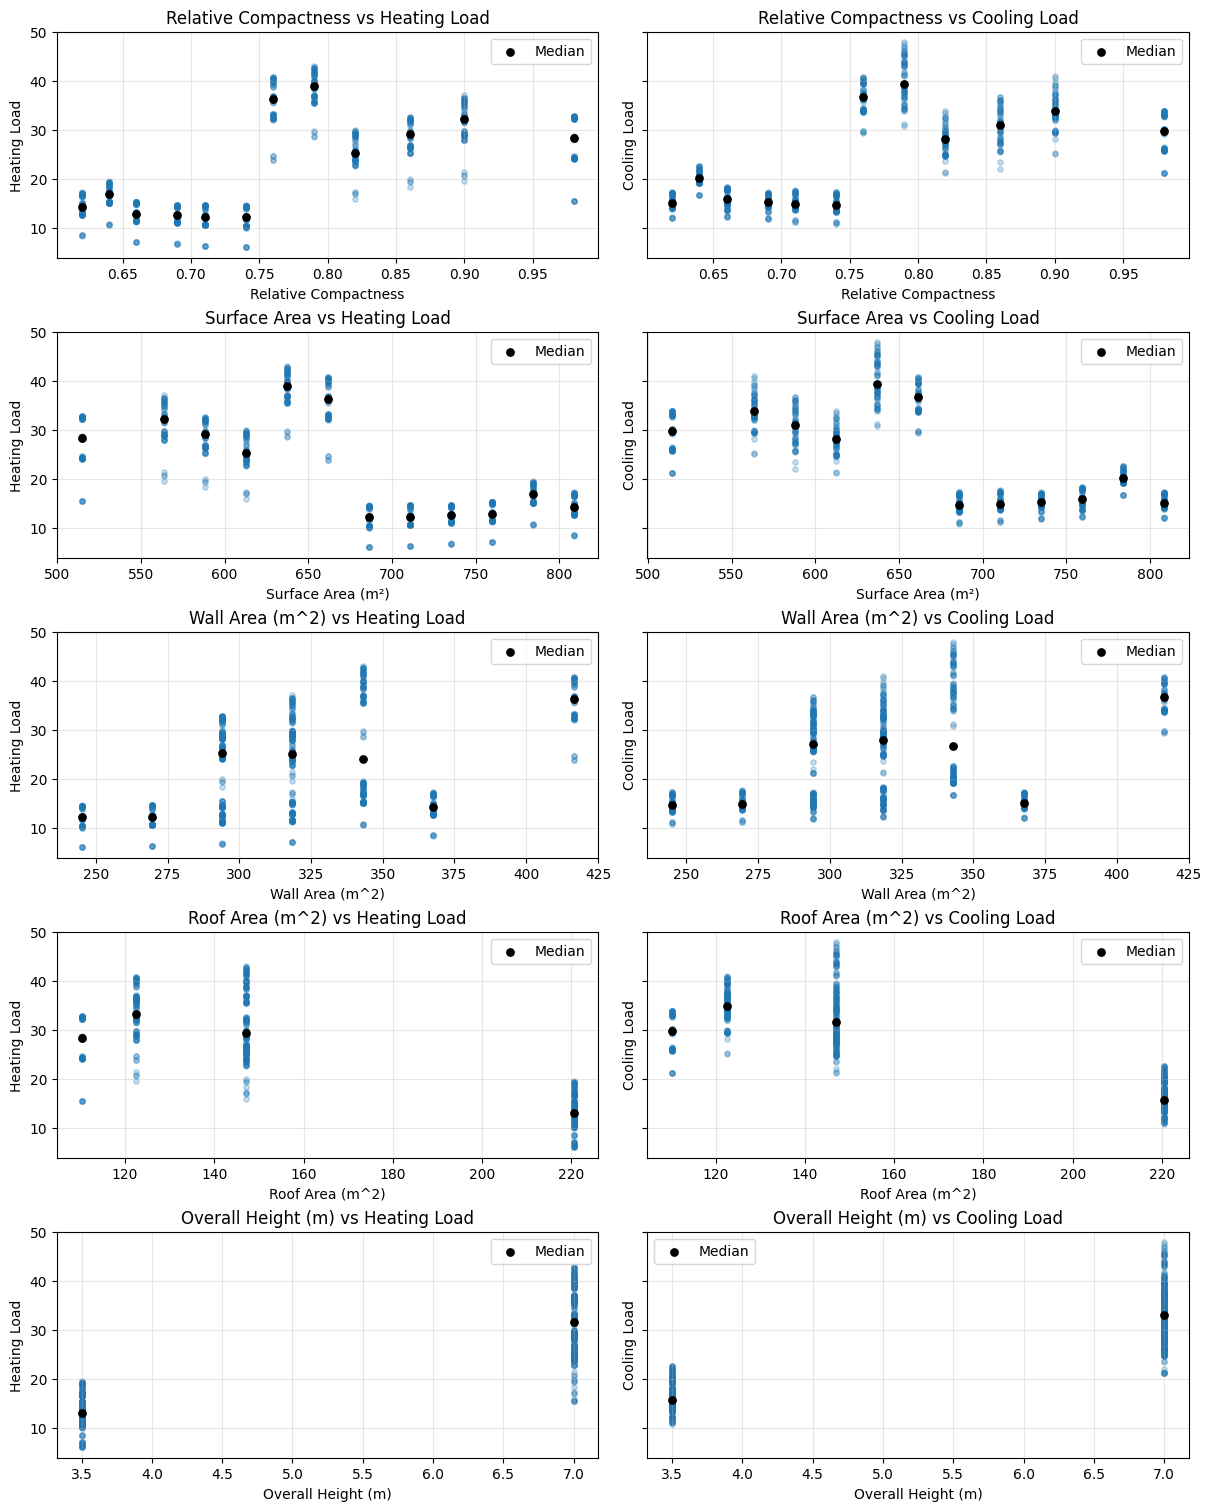

In [202]:
features = ['Relative Compactness',
                    'Surface Area',
                    'Wall Area (m^2)',
                    'Roof Area (m^2)',
                    'Overall Height (m)',
]
targets = ['Heating Load', 'Cooling Load']

fig, axes = plt.subplots(
    len(features), 2,
    figsize=(12, 3 * len(features)),
    sharey= 'row',
    constrained_layout=True
)

for row, feature in enumerate(features):
    for col, target in enumerate(targets):
        ax = axes[row, col]
        ax.scatter(df[feature], df[target], alpha=0.25, s=15)
        medians = df.groupby(feature)[target].median()
        ax.grid(True,alpha = .3)
        ax.scatter(medians.index, medians, color='black', s=28, zorder=3, label='Median')

        ax.legend()
        ax.set_xlabel('Surface Area (m²)' if feature == 'Surface Area' else feature)
        ax.set_ylabel(target)
        ax.set_title(f'{feature} vs {target}')

plt.show()

The scatterplots show the five geometry measurements. The boxplots show heating and cooling loads by orientation and glazing distribution across all designs.

Heating and cooling loads show similar relationships with the building geometry features. Relative compactness and wall area have positive associations with both targets, while surface area and roof area have negative associations. However, the plots contain distinct clusters and nonlinear patterns, suggesting that individual features do not fully explain energy demand and should be considered collectively.

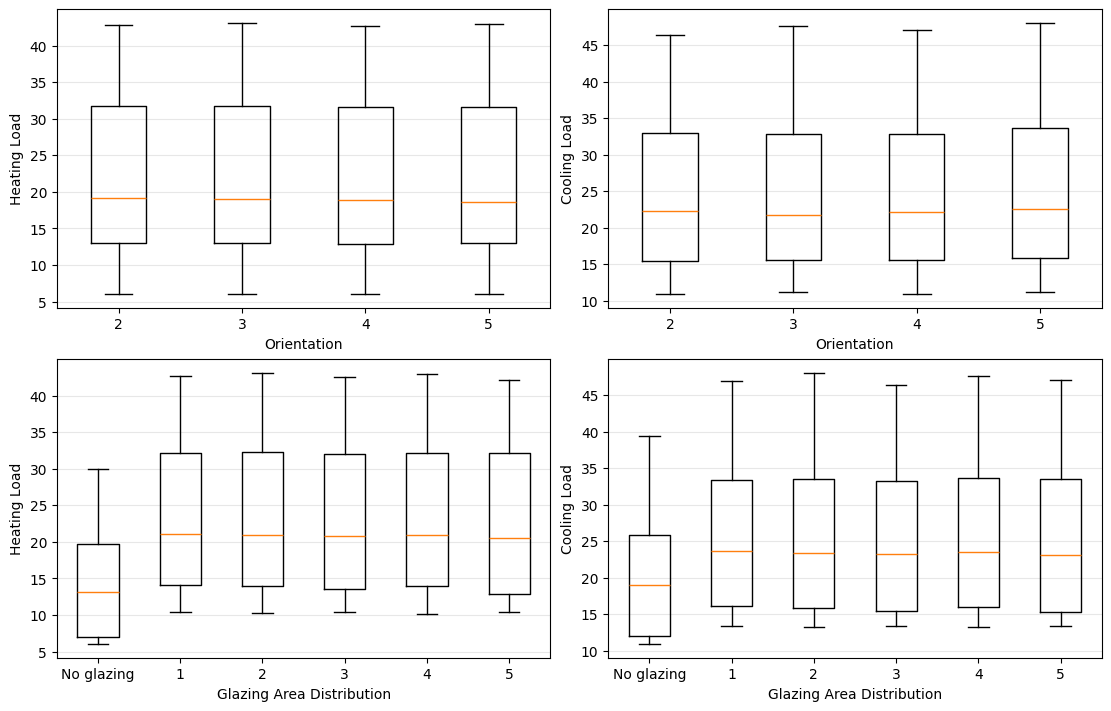

In [203]:
categorical_features = ["Orientation", "Glazing Area Distribution"]
targets = ["Heating Load", "Cooling Load"]

fig, axes = plt.subplots(
    len(categorical_features), len(targets),
    figsize=(11, 7),
    sharey="col",
    constrained_layout=True,
)

for row, feature in enumerate(categorical_features):
    groups = list(df.groupby(feature, observed=True))
    labels = [
        "No glazing" if feature == "Glazing Area Distribution" and category == 0
        else f"{category:g}"
        for category, _ in groups
    ]
    for col, target in enumerate(targets):
        ax = axes[row, col]
        ax.boxplot([designs[target] for _, designs in groups])
        ax.set_xticks(range(1, len(labels) + 1), labels)
        ax.set_xlabel(feature)
        ax.set_ylabel(target)
        ax.grid(axis="y", alpha=0.3)

plt.show()

Median heating and cooling loads are similar across orientations. Designs without glazing have lower median loads than designs in each of the five glazing-layout categories. These boxplots pool designs across shapes and glazing amounts. The no-glazing comparison reflects whether windows are present.

In [204]:
# Pearson correlations for numeric predictors
targets = ["Heating Load", "Cooling Load"]
numeric_features = df.drop(columns=targets).select_dtypes(include="number").columns

corr_table = df[numeric_features.tolist() + targets].corr(method="pearson").loc[numeric_features, targets]
display(corr_table.round(2))

,Heating Load,Cooling Load
Relative Compactness,0.62,0.63
Surface Area,-0.66,-0.67
Wall Area (m^2),0.46,0.43
Roof Area (m^2),-0.86,-0.86
Overall Height (m),0.89,0.90
Glazing Area,0.27,0.21


Overall Height & Roof Area had the strongest correlations among the numeric features examined.

### Pearson correlations for categorical predictors

For each category, use a binary indicator that is 1 when a design belongs to that category and 0 otherwise. Pearson correlation with this indicator compares that category with all other designs. A positive value means the category has a higher average load than the remaining designs. These comparisons pool shapes and other design settings.

In [205]:
categorical_features = ["Orientation", "Glazing Area Distribution"]

category_indicators = pd.get_dummies(df[categorical_features], dtype=int)
category_indicators = category_indicators.rename(
    columns={"Glazing Area Distribution_0.0": "Glazing Area Distribution: No glazing"}
)

category_corr = pd.concat([category_indicators, df[targets]], axis=1).corr(method="pearson")
category_corr = category_corr.loc[category_indicators.columns, targets]
display(category_corr.round(2))

,Heating Load,Cooling Load
Orientation_2.0,0.00,0.00
Orientation_3.0,0.00,-0.02
Orientation_4.0,-0.00,-0.01
Orientation_5.0,-0.00,0.02
Glazing Area Distribution: No glazing,-0.21,-0.13
Glazing Area Distribution_1.0,0.03,0.03
Glazing Area Distribution_2.0,0.03,0.02
Glazing Area Distribution_3.0,0.02,0.00
Glazing Area Distribution_4.0,0.03,0.02
Glazing Area Distribution_5.0,0.02,0.01


In [206]:
#correlation
targets = ["Heating Load", "Cooling Load"]
corr_table = df[targets].corr(method="pearson")
display(corr_table.round(2))

,Heating Load,Cooling Load
Heating Load,1.00,0.98
Cooling Load,0.98,1.00


# EDA Findings

- **Heating and cooling loads tend to rise together.** Across the simulated designs, Pearson correlation was 0.976 and Spearman correlation was 0.973. Using the bottom and top quartiles to define low and high loads, 167 of 192 low-cooling designs (87.0%) also had low heating loads, and none had high heating loads. Among the 192 high-cooling designs, 166 (86.5%) also had high heating loads, and none had low heating loads.
- **Height and roof area had the strongest associations among the geometry features examined.** Overall height was positively associated with both loads (Pearson r = +0.89 for heating and +0.90 for cooling), and roof area was negatively associated with both (r = −0.86 for each). Relative compactness and wall area were positively associated with both loads, while surface area was negatively associated. The geometry measurements vary together, so these correlations cannot isolate the effect of changing an individual feature.
- **Median loads were similar across orientations.** Designs without glazing had lower median loads than designs in each glazing-layout category. The boxplots compare pooled designs, so the difference for the no-glazing group cannot isolate the effect of glazing layout.
- **Cooling loads were typically higher than heating loads.** The median simulated cooling load was 22.08, compared with 18.95 for heating. Both distributions showed multiple peaks and were slightly right-skewed.

The quartile comparisons pool all shapes. Comparing variants within the same shape would help clarify how glazing and orientation relate to the loads.